# Milestone 1: Data Cleaning & Preparation
**DATA 101 – Term Project** · Miguel Angel Albarracin Ospina

**Research question:** *How do body weight and age affect the amount of weight powerlifters can lift?*

**Dataset:** [OpenPowerlifting](https://www.openpowerlifting.org) – an open database of results from powerlifting competitions around the world.
Data page: <https://www.openpowerlifting.org/data.html> · Kaggle copy: <https://www.kaggle.com/datasets/open-powerlifting/powerlifting-database>


In [3]:
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"

In [4]:
# Path to the OpenPowerlifting CSV. Change it if your file has another name or folder.
DATA_PATH = "openpowerlifting-latest.csv"

matches = sorted(glob.glob("openpowerlifting-*.csv"))
if matches:
    DATA_PATH = matches[0]
print("Reading:", DATA_PATH)

Reading: openpowerlifting-2026-10-17-c7782562.csv


## 1. Load the data and take a first look
The full file has about 40 columns. My question only needs a few of them, so I choose them with `usecols`. This keeps the notebook fast and keeps the memory use low.

In [5]:
USE_COLS = [
    "Name", "Sex", "Event", "Equipment", "Age", "BodyweightKg", "WeightClassKg",
    "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg", "TotalKg",
    "Place", "Dots", "Tested", "Federation", "Country", "Date", "MeetName",
]

raw = pd.read_csv(DATA_PATH, usecols=USE_COLS, low_memory=False)
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw data: 4,050,248 rows x 18 columns


,Name,Sex,Event,Equipment,Age,BodyweightKg,WeightClassKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg,TotalKg,Place,Dots,Tested,Country,Federation,Date,MeetName
0,E.S. Denisenko,F,B,Raw,28.50,67.30,NaN,NaN,NaN,NaN,NaN,DQ,NaN,NaN,Belarus,GSF-Belarus,2019-06-22,Bison Power Cup
1,I.S. Lebetskaya,F,B,Raw,43.50,73.20,NaN,NaN,90.00,NaN,90.00,1,88.80,NaN,Belarus,GSF-Belarus,2019-06-22,Bison Power Cup
2,K. Yakimovich,F,B,Raw,26.50,60.60,NaN,NaN,45.00,NaN,45.00,2,49.57,NaN,Belarus,GSF-Belarus,2019-06-22,Bison Power Cup
3,A.G. Golneva,F,B,Raw,19.50,50.30,NaN,NaN,35.00,NaN,35.00,2,43.67,NaN,Belarus,GSF-Belarus,2019-06-22,Bison Power Cup
4,E.V. Marunevskaya,F,B,Raw,19.50,63.70,NaN,NaN,42.50,NaN,42.50,1,45.40,NaN,Belarus,GSF-Belarus,2019-06-22,Bison Power Cup


In [6]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4050248 entries, 0 to 4050247
Data columns (total 18 columns):
 #   Column           Dtype  
---  ------           -----  
 0   Name             object 
 1   Sex              object 
 2   Event            object 
 3   Equipment        object 
 4   Age              float64
 5   BodyweightKg     float64
 6   WeightClassKg    object 
 7   Best3SquatKg     float64
 8   Best3BenchKg     float64
 9   Best3DeadliftKg  float64
 10  TotalKg          float64
 11  Place            object 
 12  Dots             float64
 13  Tested           object 
 14  Country          object 
 15  Federation       object 
 16  Date             object 
 17  MeetName         object 
dtypes: float64(7), object(11)
memory usage: 556.2+ MB


### Missing values in the raw data
Before changing anything I want to know how much is missing in each column.

In [7]:
missing = raw.isna().sum().to_frame("missing")
missing["percent"] = missing["missing"] / len(raw) * 100
missing.sort_values("percent", ascending=False)

,missing,percent
Age,1463660,36.14
Best3SquatKg,1228579,30.33
Best3DeadliftKg,1019502,25.17
Tested,962351,23.76
Best3BenchKg,455857,11.26
Dots,297174,7.34
TotalKg,270938,6.69
Country,100283,2.48
WeightClassKg,59878,1.48
BodyweightKg,44455,1.10


In [8]:
for col in ["Sex", "Event", "Equipment", "Tested"]:
    print(f"--- {col} ---")
    print(raw[col].value_counts(dropna=False).head(10), "\n")

--- Sex ---
Sex
M     2917030
F     1133019
Mx        199
Name: count, dtype: int64 

--- Event ---
Event
SBD    2925027
B       802815
D       219805
BD       75966
S        19960
SB        4185
SD        2490
Name: count, dtype: int64 

--- Equipment ---
Equipment
Raw           1935362
Single-ply    1416353
Unlimited      324522
Wraps          242582
Multi-ply      131310
Straps            119
Name: count, dtype: int64 

--- Tested ---
Tested
Yes    3087897
NaN     962351
Name: count, dtype: int64 



**First observations (raw data)**
- `Event` tells which lifts the person did. `SBD` means **S**quat, **B**ench and **D**eadlift (a full powerlifting meet). Other values are bench-only, deadlift-only, etc. My question is about the *total* lifted, so I need `SBD`.
- `Equipment` tells if the lifter used supportive gear (wraps, single-ply, multi-ply suits). Gear changes how much a person can lift, so mixing it with `Raw` lifters would not be a fair comparison.
- `Age` and `BodyweightKg` have missing values. Without them a row is useless for my question.
- `TotalKg` is empty when the lifter failed to complete a valid total (for example, disqualified).

## 2. Data cleaning
I work on a copy (`df`) so the raw data stays untouched. I also keep a small **cleaning log** with the number of rows after each step, so the effect of every decision is visible.

In [9]:
df = raw.copy()
log = [{"step": "Raw file", "rows": len(df)}]


def record(step, frame):
    log.append({"step": step, "rows": len(frame)})

### Step 2.1 – Standardize formats
- Remove extra spaces in text columns and make `Sex` upper-case, so `"m "` and `"M"` are not treated as different values.
- Convert `Date` to a real date type and create a `Year` column.

In [10]:
text_cols = ["Name", "Sex", "Event", "Equipment", "Place", "Tested", "Federation", "Country", "MeetName"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

df["Sex"] = df["Sex"].str.upper()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Year"] = df["Date"].dt.year

print("Dates that could not be read:", int(df["Date"].isna().sum()))
print("Sex values:", df["Sex"].value_counts(dropna=False).to_dict())

Dates that could not be read: 0
Sex values: {'M': 2917030, 'F': 1133019, 'MX': 199}


### Step 2.2 – Keep only the rows that match my question
| Filter | Why |
|---|---|
| `Sex` is `M` or `F` | The dataset also has a small non-binary group (`Mx`). It is too small to compare reliably, so I leave it out of this analysis. |
| `Event == "SBD"` | Full meets with squat + bench + deadlift, so `TotalKg` means the same thing for everyone. |
| `Equipment == "Raw"` | No supportive gear = fair comparison, and it is also the closest to how most people train. |
| `Place != "DQ"` | Disqualified results do not have a valid total. |

In [11]:
df = df[df["Sex"].isin(["M", "F"])]
record("Keep Sex = M or F", df)

df = df[df["Event"] == "SBD"]
record("Keep Event = SBD (full meets)", df)

df = df[df["Equipment"] == "Raw"]
record("Keep Equipment = Raw", df)

df = df[df["Place"].fillna("").ne("DQ")]
record("Remove disqualified (DQ)", df)

pd.DataFrame(log)

,step,rows
0,Raw file,4050248
1,Keep Sex = M or F,4050049
2,Keep Event = SBD (full meets),2924859
3,Keep Equipment = Raw,1193224
4,Remove disqualified (DQ),1147747


### Step 2.3 – Handle missing values
A row without age, body weight or lifts cannot answer my question, and I cannot guess these values honestly (making up someone's age would add fake information). So I **drop** these rows instead of filling them in.

The columns `Dots` (a score that adjusts the total for body weight) and `WeightClassKg` are not needed for the filter, so I leave their missing values as they are and just report them later.

In [12]:
required = ["Age", "BodyweightKg", "TotalKg", "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]
print("Missing values in required columns before dropping:")
print(df[required].isna().sum(), "\n")

df = df.dropna(subset=required)
record("Drop rows missing age, bodyweight or lifts", df)
pd.DataFrame(log)

Missing values in required columns before dropping:
Age                162262
BodyweightKg         2321
TotalKg              2782
Best3SquatKg         2694
Best3BenchKg         2746
Best3DeadliftKg      2697
dtype: int64 



,step,rows
0,Raw file,4050248
1,Keep Sex = M or F,4050049
2,Keep Event = SBD (full meets),2924859
3,Keep Equipment = Raw,1193224
4,Remove disqualified (DQ),1147747
5,"Drop rows missing age, bodyweight or lifts",982296


### Step 2.4 – Remove impossible or suspicious values
I set simple, reasonable limits. These are my own decisions and they are written here so they can be changed later:
- **Age between 14 and 90.** (Some ages end in `.5`. In OpenPowerlifting this means the exact birthday is unknown and the age is an estimate, so I keep decimals.)
- **Body weight between 35 kg and 250 kg.**
- **All three best lifts and the total must be greater than 0.**

In [13]:
valid = (
    df["Age"].between(14, 90)
    & df["BodyweightKg"].between(35, 250)
    & (df["TotalKg"] > 0)
    & (df["Best3SquatKg"] > 0)
    & (df["Best3BenchKg"] > 0)
    & (df["Best3DeadliftKg"] > 0)
)
print(f"Rows outside the limits: {(~valid).sum():,}")

df = df[valid]
record("Remove impossible values (age, bodyweight, lifts)", df)
pd.DataFrame(log)

Rows outside the limits: 12,463


,step,rows
0,Raw file,4050248
1,Keep Sex = M or F,4050049
2,Keep Event = SBD (full meets),2924859
3,Keep Equipment = Raw,1193224
4,Remove disqualified (DQ),1147747
5,"Drop rows missing age, bodyweight or lifts",982296
6,"Remove impossible values (age, bodyweight, lifts)",969833


### Step 2.5 – Remove duplicates
The same result should not appear twice. I call two rows duplicates when the lifter, meet, date, federation, age, body weight and total are all the same.

In [14]:
dup_cols = ["Name", "Date", "MeetName", "Federation", "Sex", "Age", "BodyweightKg", "TotalKg"]
n_dups = int(df.duplicated(subset=dup_cols).sum())
print(f"Duplicate rows found: {n_dups:,}")

df = df.drop_duplicates(subset=dup_cols)
record("Remove duplicate results", df)
pd.DataFrame(log)

Duplicate rows found: 67,651


,step,rows
0,Raw file,4050248
1,Keep Sex = M or F,4050049
2,Keep Event = SBD (full meets),2924859
3,Keep Equipment = Raw,1193224
4,Remove disqualified (DQ),1147747
5,"Drop rows missing age, bodyweight or lifts",982296
6,"Remove impossible values (age, bodyweight, lifts)",969833
7,Remove duplicate results,902182


## 3. Derived features
New columns that make the analysis easier:

- **`AgeGroup`** – age grouped in ranges. Grouping makes patterns easier to see than 80 different ages.
- **`BodyweightGroup`** – body weight grouped in ranges of about 10 kg.
- **`TotalToBodyweight`** – total lifted divided by body weight. This is a simple way to measure *relative strength* (how much someone lifts for their size).
- **`IsTested`** – `True` if the federation does drug testing (from the `Tested` column; blank values are treated as `False`).

In [15]:
age_bins = [14, 18, 20, 25, 30, 35, 40, 50, 60, 100]
age_labels = ["14-17", "18-19", "20-24", "25-29", "30-34", "35-39", "40-49", "50-59", "60+"]
df["AgeGroup"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=False)

bw_bins = [35, 60, 70, 80, 90, 100, 110, 125, 251]
bw_labels = ["35-59", "60-69", "70-79", "80-89", "90-99", "100-109", "110-124", "125+"]
df["BodyweightGroup"] = pd.cut(df["BodyweightKg"], bins=bw_bins, labels=bw_labels, right=False)

df["TotalToBodyweight"] = df["TotalKg"] / df["BodyweightKg"]
df["IsTested"] = df["Tested"].fillna("No").eq("Yes")

# Smaller, faster data types
for col in ["Sex", "Federation", "Country", "Equipment", "Event"]:
    df[col] = df[col].astype("category")
for col in ["Age", "BodyweightKg", "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg", "TotalKg", "Dots", "TotalToBodyweight"]:
    df[col] = df[col].astype("float32")
df["Year"] = df["Year"].astype("Int16")

df = df.reset_index(drop=True)
df[["Sex", "Age", "AgeGroup", "BodyweightKg", "BodyweightGroup", "TotalKg", "TotalToBodyweight", "IsTested"]].head()

,Sex,Age,AgeGroup,BodyweightKg,BodyweightGroup,TotalKg,TotalToBodyweight,IsTested
0,M,33.00,30-34,136.60,125+,955.00,6.99,False
1,M,32.00,30-34,131.00,125+,985.00,7.52,False
2,M,39.50,35-39,109.65,100-109,640.00,5.84,True
3,M,27.50,25-29,86.00,80-89,690.00,8.02,False
4,M,24.00,20-24,99.30,90-99,600.00,6.04,True


### Quick checks
These `assert` lines stop the notebook if something is wrong, so I do not continue with bad data.

In [16]:
assert df[required].isna().sum().sum() == 0, "There are still missing values in required columns"
assert not df.duplicated(subset=dup_cols).any(), "There are still duplicates"
assert df["AgeGroup"].notna().all() and df["BodyweightGroup"].notna().all(), "Some rows have no group"
assert set(df["Sex"].unique()) <= {"M", "F"}
print("All checks passed.")
pd.DataFrame(log).assign(removed=lambda t: t["rows"].diff().fillna(0).astype(int))

All checks passed.


,step,rows,removed
0,Raw file,4050248,0
1,Keep Sex = M or F,4050049,-199
2,Keep Event = SBD (full meets),2924859,-1125190
3,Keep Equipment = Raw,1193224,-1731635
4,Remove disqualified (DQ),1147747,-45477
5,"Drop rows missing age, bodyweight or lifts",982296,-165451
6,"Remove impossible values (age, bodyweight, lifts)",969833,-12463
7,Remove duplicate results,902182,-67651


## 4. Initial exploratory analysis
A first look at the clean data. The goal here is only to understand it and see if the question makes sense. The deeper visualizations come in Milestone 2.

In [17]:
num_cols = ["Age", "BodyweightKg", "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg", "TotalKg", "TotalToBodyweight"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"902,182.00",28.63,11.58,14.00,20.50,25.00,33.00,90.00
BodyweightKg,"902,182.00",83.20,20.86,35.00,67.50,81.25,95.10,246.80
Best3SquatKg,"902,182.00",168.74,58.20,10.00,122.50,167.50,210.00,490.50
Best3BenchKg,"902,182.00",108.05,42.14,6.80,70.00,110.00,140.00,325.00
Best3DeadliftKg,"902,182.00",195.45,58.72,20.00,147.50,197.50,240.00,492.50
TotalKg,"902,182.00",472.24,154.31,47.50,342.50,475.00,585.00,"1,225.00"
TotalToBodyweight,"902,182.00",5.70,1.41,0.55,4.71,5.73,6.68,12.16


In [18]:
print("Rows per sex:")
print(df["Sex"].value_counts(), "\n")
print("Rows per age group:")
print(df["AgeGroup"].value_counts().sort_index(), "\n")
print("Rows per bodyweight group:")
print(df["BodyweightGroup"].value_counts().sort_index())

Rows per sex:
Sex
M    603631
F    298551
Name: count, dtype: int64 

Rows per age group:
AgeGroup
14-17    106475
18-19     86208
20-24    237375
25-29    166937
30-34    104135
35-39     60697
40-49     76510
50-59     39339
60+       24506
Name: count, dtype: int64 

Rows per bodyweight group:
BodyweightGroup
35-59      110914
60-69      139969
70-79      164887
80-89      191185
90-99      124527
100-109     83395
110-124     54859
125+        32446
Name: count, dtype: int64


In [19]:
# Average results by sex
df.groupby("Sex", observed=True)[["Age", "BodyweightKg", "TotalKg", "TotalToBodyweight"]].agg(["mean", "median"])

Age        BodyweightKg        TotalKg        TotalToBodyweight       
     mean median         mean median    mean median              mean median
Sex                                                                         
F   30.11  27.00        70.12  66.90  316.01 312.50              4.64   4.59
M   27.90  24.50        89.67  87.95  549.52 547.50              6.23   6.24

In [20]:
# Median total by age group and sex
age_table = df.pivot_table(index="AgeGroup", columns="Sex", values="TotalKg", aggfunc=["median", "count"], observed=False)
age_table

median         count        
Sex           F      M      F       M
AgeGroup                             
14-17    265.00 445.00  28621   77854
18-19    302.50 522.50  21831   64377
20-24    322.50 567.50  70674  166701
25-29    330.00 590.00  56415  110522
30-34    327.50 595.00  38616   65519
35-39    322.50 585.00  25374   35323
40-49    310.00 555.00  33497   43013
50-59    280.00 502.50  15622   23717
60+      237.50 407.50   7901   16605

In [21]:
# Median total by body weight group and sex
bw_table = df.pivot_table(index="BodyweightGroup", columns="Sex", values="TotalKg", aggfunc=["median", "count"], observed=False)
bw_table

median         count        
Sex                  F      M      F       M
BodyweightGroup                             
35-59           275.00 372.50  88203   22711
60-69           312.50 442.50  87743   52226
70-79           330.00 495.00  55883  109004
80-89           342.50 546.00  34558  156627
90-99           345.00 585.00  13385  111142
100-109         355.00 617.50   8323   75072
110-124         372.50 643.00   6498   48361
125+            400.00 672.50   3958   28488

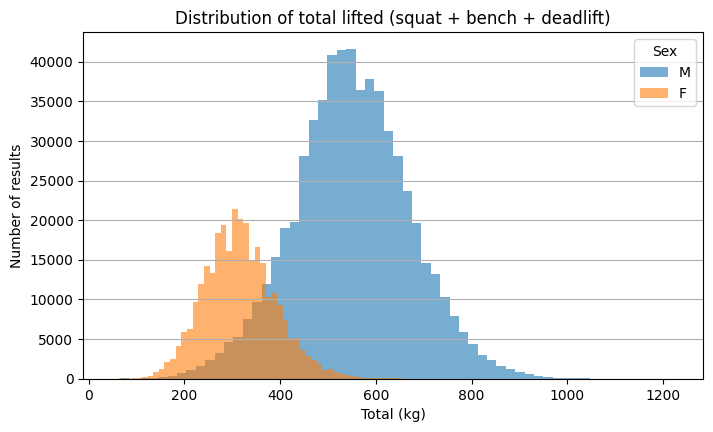

In [22]:
# Plot 1: how are the totals distributed?
fig, ax = plt.subplots()
for sex, color in [("M", "tab:blue"), ("F", "tab:orange")]:
    ax.hist(df.loc[df["Sex"] == sex, "TotalKg"], bins=60, alpha=0.6, label=sex, color=color)
ax.set_title("Distribution of total lifted (squat + bench + deadlift)")
ax.set_xlabel("Total (kg)")
ax.set_ylabel("Number of results")
ax.legend(title="Sex")
plt.show()

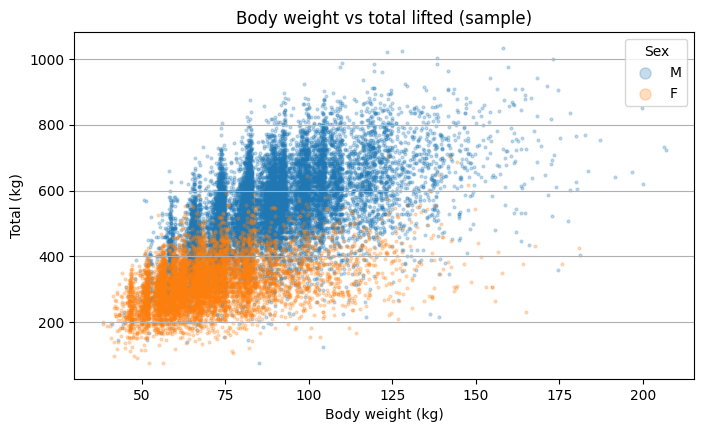

In [23]:
# Plot 2: body weight vs total (random sample so the plot stays readable)
sample = df.sample(n=min(20000, len(df)), random_state=42)
fig, ax = plt.subplots()
for sex, color in [("M", "tab:blue"), ("F", "tab:orange")]:
    part = sample[sample["Sex"] == sex]
    ax.scatter(part["BodyweightKg"], part["TotalKg"], s=4, alpha=0.25, label=sex, color=color)
ax.set_title("Body weight vs total lifted (sample)")
ax.set_xlabel("Body weight (kg)")
ax.set_ylabel("Total (kg)")
ax.legend(title="Sex", markerscale=4)
plt.show()

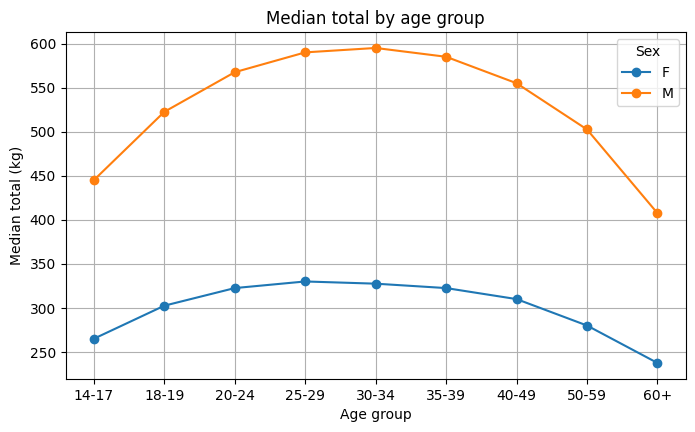

In [24]:
# Plot 3: median total by age group
med = df.groupby(["AgeGroup", "Sex"], observed=True)["TotalKg"].median().unstack("Sex")
ax = med.plot(marker="o")
ax.set_title("Median total by age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Median total (kg)")
plt.show()

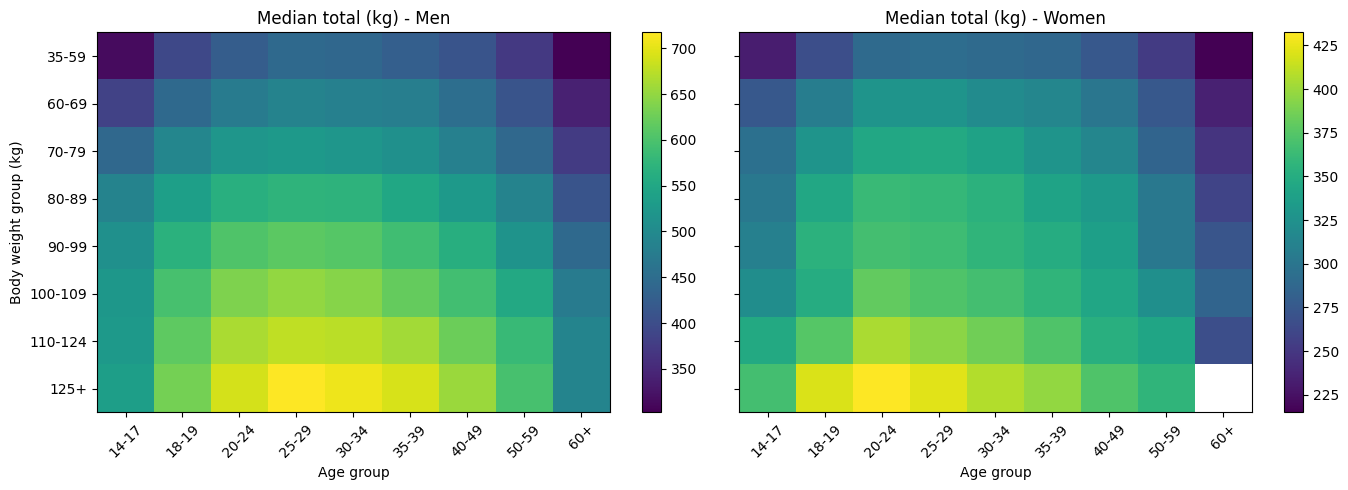

In [25]:
# Plot 4: median total for every age group x body weight group
# Groups with fewer than 30 results are left blank because they are not reliable.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, sex in zip(axes, ["M", "F"]):
    part = df[df["Sex"] == sex]
    pt = part.pivot_table(index="BodyweightGroup", columns="AgeGroup", values="TotalKg", aggfunc="median", observed=False)
    cnt = part.pivot_table(index="BodyweightGroup", columns="AgeGroup", values="TotalKg", aggfunc="count", observed=False)
    pt = pt.where(cnt >= 30)
    im = ax.imshow(pt.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(pt.columns)))
    ax.set_xticklabels(pt.columns, rotation=45)
    ax.set_yticks(range(len(pt.index)))
    ax.set_yticklabels(pt.index)
    ax.set_title(f"Median total (kg) - {'Men' if sex == 'M' else 'Women'}")
    ax.set_xlabel("Age group")
    ax.grid(False)
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Body weight group (kg)")
plt.tight_layout()
plt.show()

In [26]:
# How strongly are age / body weight related to the total? (correlation, not proof of cause)
for sex in ["M", "F"]:
    part = df[df["Sex"] == sex]
    print(f"Correlation with total - {sex}")
    print(part[["Age", "BodyweightKg", "TotalKg"]].corr()["TotalKg"].drop("TotalKg").round(2).to_string(), "\n")

Correlation with total - M
Age            0.00
BodyweightKg   0.55 

Correlation with total - F
Age            -0.07
BodyweightKg    0.40 



### Where would I land?
Just for fun and to make the data feel real: this compares the typical lifter in my own age and weight range. Remember that people who enter powerlifting meets train specifically for strength, so they are **stronger than the average person at the gym**.

In [27]:
MY_SEX = "M"           # change to "F" if needed
MY_AGE_GROUP = "18-19"
MY_BW_GROUP = "70-79"  # I weigh about 73 kg

mine = df[(df["Sex"] == MY_SEX) & (df["AgeGroup"] == MY_AGE_GROUP) & (df["BodyweightGroup"] == MY_BW_GROUP)]
print(f"Lifters in my group (sex {MY_SEX}, age {MY_AGE_GROUP}, {MY_BW_GROUP} kg): {len(mine):,}")
if len(mine):
    print(mine[["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg", "TotalKg"]].median().round(1).to_string())

Lifters in my group (sex M, age 18-19, 70-79 kg): 15,564
Best3SquatKg      175.00
Best3BenchKg      110.00
Best3DeadliftKg   205.00
TotalKg           492.50


## Save the cleaned dataset
The full cleaned file is big, so I save it compressed (`.csv.gz`). I also save a small random sample (10,000 rows) that is easy to open and to upload to GitHub. GitHub does not accept single files larger than 100 MB, so the full file should stay on my computer, and the link to the original dataset (above) is the reference for the full data.

In [28]:
df.to_csv("openpowerlifting_clean.csv.gz", index=False, compression="gzip")
df.sample(n=min(10000, len(df)), random_state=42).to_csv("openpowerlifting_clean_sample.csv", index=False)
print(f"Saved {len(df):,} cleaned rows.")

Saved 902,182 cleaned rows.


## 5. Summary of the dataset and key observations
The text below is generated from the data, so the numbers always match the cleaned dataset.

In [29]:
n_rows = len(df)
n_lifters = df["Name"].nunique()
share_male = (df["Sex"] == "M").mean() * 100
year_min, year_max = int(df["Year"].min()), int(df["Year"].max())
kept_pct = n_rows / len(raw) * 100

med_total = df.groupby("Sex", observed=True)["TotalKg"].median()
med_ratio = df.groupby("Sex", observed=True)["TotalToBodyweight"].median()
age_med = df.groupby(["Sex", "AgeGroup"], observed=True)["TotalKg"].median()
peak_age = {s: age_med[s].idxmax() for s in ["M", "F"]}
corr_bw = {s: df.loc[df["Sex"] == s, ["BodyweightKg", "TotalKg"]].corr().iloc[0, 1] for s in ["M", "F"]}
corr_age = {s: df.loc[df["Sex"] == s, ["Age", "TotalKg"]].corr().iloc[0, 1] for s in ["M", "F"]}

display(Markdown(f"""
**Cleaned dataset in numbers**
- **{n_rows:,}** results from **{n_lifters:,}** different lifters ({kept_pct:.1f}% of the {len(raw):,} raw rows were kept).
- Meets from **{year_min}** to **{year_max}**. About **{share_male:.0f}%** of the results are from men.
- Median total: **{med_total['M']:.0f} kg** for men and **{med_total['F']:.0f} kg** for women.
- Median total divided by body weight: **{med_ratio['M']:.2f}** for men and **{med_ratio['F']:.2f}** for women.

**Key observations**
1. **Body weight and strength go together.** The correlation between body weight and total is **{corr_bw['M']:.2f}** for men and **{corr_bw['F']:.2f}** for women, so heavier lifters tend to lift more.
2. **Age is not a simple straight line.** The correlation between age and total is **{corr_age['M']:.2f}** for men and **{corr_age['F']:.2f}** for women. A single number like this can hide a curve (up, then down), so I compare age groups instead. The age group with the highest median total is **{peak_age['M']}** for men and **{peak_age['F']}** for women.
3. **Men and women have different distributions.** I will keep them separate in the next milestones.
4. **Some groups are small.** Very light, very heavy and very old lifters have fewer results, so I need to be careful when comparing them.
"""))


**Cleaned dataset in numbers**
- **902,182** results from **341,823** different lifters (22.3% of the 4,050,248 raw rows were kept).
- Meets from **1965** to **2026**. About **67%** of the results are from men.
- Median total: **548 kg** for men and **312 kg** for women.
- Median total divided by body weight: **6.24** for men and **4.59** for women.

**Key observations**
1. **Body weight and strength go together.** The correlation between body weight and total is **0.55** for men and **0.40** for women, so heavier lifters tend to lift more.
2. **Age is not a simple straight line.** The correlation between age and total is **0.00** for men and **-0.07** for women. A single number like this can hide a curve (up, then down), so I compare age groups instead. The age group with the highest median total is **30-34** for men and **25-29** for women.
3. **Men and women have different distributions.** I will keep them separate in the next milestones.
4. **Some groups are small.** Very light, very heavy and very old lifters have fewer results, so I need to be careful when comparing them.


### Data dictionary (columns I kept or created)
| Column | Meaning |
|---|---|
| `Name` | Lifter name |
| `Sex` | `M` or `F` (as listed by the federation) |
| `Event` | Lifts performed (`SBD` = squat, bench, deadlift) |
| `Equipment` | Gear used (`Raw` = none) |
| `Age` | Age at the meet (`.5` = estimated) |
| `BodyweightKg` | Body weight at weigh-in, in kg |
| `WeightClassKg` | Official weight class |
| `Best3SquatKg`, `Best3BenchKg`, `Best3DeadliftKg` | Best successful attempt of each lift, in kg |
| `TotalKg` | Sum of the three best lifts, in kg |
| `Place` | Final placing in the meet |
| `Dots` | Strength score that adjusts the total for body weight |
| `Tested` | Whether the federation drug tests |
| `Federation`, `Country`, `MeetName`, `Date` | Where and when the result happened |
| `Year` | **New** – year of the meet |
| `AgeGroup` | **New** – age range |
| `BodyweightGroup` | **New** – body weight range |
| `TotalToBodyweight` | **New** – total ÷ body weight |
| `IsTested` | **New** – `True` / `False` version of `Tested` |

## 6. Reflection

### Why I chose this dataset
I chose OpenPowerlifting because I train regularly and strength training is something I really care about. I weigh around 80 kg and I am 19 years old, so when I look at this data I can actually picture myself in it. Most of my training is focused on building muscle size, not on competing, so I never really knew what a "strong" number is for someone with my age and weight. Social media is full of people showing huge lifts, and it is hard to know what is normal. This dataset gives me real results from real competitions, so I can see the truth with numbers instead of guessing.

### What I am curious to find out
- Does a heavier person always lift more, or does the improvement slow down after some weight?
- At what age do people reach their strongest total? Are people my age already close to their peak, or still far from it?
- Is the pattern the same for men and women?
- Who is stronger *for their size*? That is why I created the `TotalToBodyweight` column.

I am also studying psychology, so I like to ask *why* something happens. This data cannot tell me why (for example motivation, how many years someone has trained, sleep, or recovery), but it can show me **what** patterns exist, and that gives me better questions to ask.

### What I learned while cleaning the data
- **Real data is messy and very big.** The raw file has millions of rows and many columns I did not need. I could not just open it, so I learned to load only the columns I needed.
- **Most rows were not useful for my exact question.** Many lifters only did bench press, used supportive gear, were disqualified, or had no age listed. I decided what to keep and wrote down the reason for each decision, and I made a cleaning log so I can see how many rows each step removed.
- **My decisions change the results.** For example, if I had kept the lifters who use gear, the totals would look higher and I would be comparing different things. This showed me why documentation is so important: another person (or me in the future) needs to know exactly what I did.
- **Missing values are not always something to fix.** I decided not to guess ages, because inventing information is worse than having less data.
- **Small details matter.** Ages that end in `.5` are estimates, and "DQ" results have no valid total. If I had not read the documentation and checked the values, I would have missed these.

### Limits I need to remember
- People who enter powerlifting meets are not average. They train for strength and chose to compete, so the results do not describe everyone.
- The same lifter can appear many times (one for each meet), so the rows are not fully independent.
- Missing ages are probably not random (some federations report them less), so removing those rows may change the group a little.
- A pattern in the data does not prove a cause.

### Skills I practiced
Attention to detail, documenting every step, and building a workflow that someone else can repeat with Python and GitHub. I also got a better idea of how real organizations have to prepare messy data before they can trust any analysis.

### Next step
For Milestone 2 I will use these cleaned columns to make visualizations (histograms, bar charts, scatterplots) and see which ones show the relationship between age, body weight and total lifted most clearly.

In [30]:
!wget -q https://openpowerlifting.gitlab.io/opl-csv/files/openpowerlifting-latest.zip
!unzip -j -o openpowerlifting-latest.zip "*.csv"

Archive:  openpowerlifting-latest.zip
  inflating: openpowerlifting-2026-10-17-c7782562.csv  
